
Task 10: DBSCAN Clustering & Outlier Detection (Mall Customer Segmentation Dataset)
● Exam Task:
1. Load the Mall Customer Segmentation dataset, extract numerical features (e.g.,
Annual Income (k$) and Spending Score (1-100)), and scale them
appropriately using StandardScaler.
2. Fit a DBSCAN model with chosen hyperparameter values (e.g., eps and
min_samples).
3. Extract and display the number of identified customer clusters as well as the
count of spatial noise/outlier points labeled as -1.
4. Create a scatter plot visualizing the clusters with distinct colors, explicitly
highlighting the detected spatial outliers/noise points1*

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN

# 1. Load the Mall Customer Segmentation dataset
# Using a reliable public URL for the Mall Customers dataset
url = 'https://raw.githubusercontent.com/tirthajyoti/Machine-Learning-with-Python/master/Datasets/Mall_Customers.csv'
df = pd.read_csv(url)

print("Dataset Columns and Head:")
display(df.head())

# Extract numerical features: Annual Income (k$) and Spending Score (1-100)
features = df[['Annual Income (k$)', 'Spending Score (1-100)']]

# Scale features appropriately using StandardScaler
scaler = StandardScaler()
scaled_features = scaler.fit_transform(features)

Dataset Columns and Head:


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [2]:
# 2. Fit a DBSCAN model with chosen hyperparameter values
# Tuning eps and min_samples for the scaled spatial space
eps_val = 0.35
min_samples_val = 5

dbscan = DBSCAN(eps=eps_val, min_samples=min_samples_val)
labels = dbscan.fit_predict(scaled_features)

# Add the cluster labels to our original dataframe
df['Cluster'] = labels

In [3]:
# 3. Extract and display the number of identified customer clusters and spatial noise points
unique_labels = set(labels)

# Number of clusters (excluding noise label -1)
n_clusters = len(unique_labels - {-1})
# Count of spatial noise/outlier points labeled as -1
n_noise = list(labels).count(-1)

print(f"Number of identified customer clusters: {n_clusters}")
print(f"Count of spatial noise/outlier points (labeled as -1): {n_noise}")

Number of identified customer clusters: 6
Count of spatial noise/outlier points (labeled as -1): 23


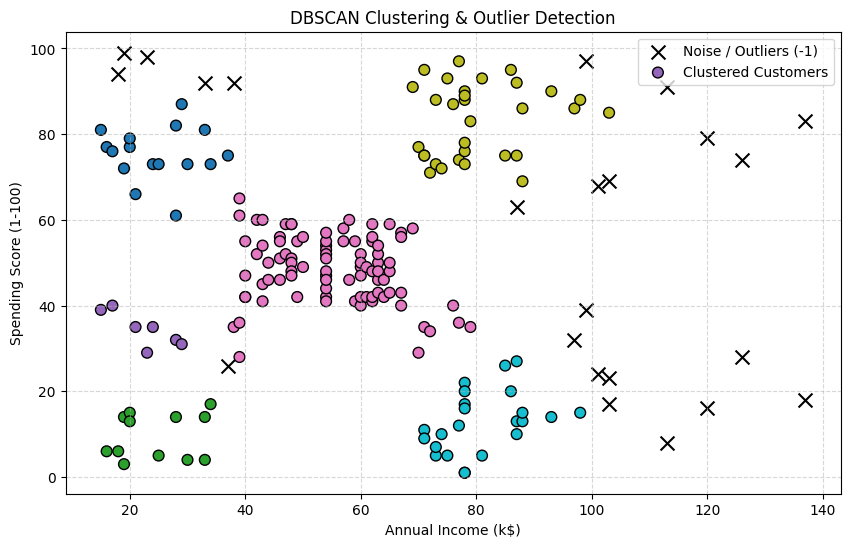

In [4]:
# 4. Create a scatter plot visualizing the clusters with distinct colors, highlighting noise
plt.figure(figsize=(10, 6))

# Plot noise/outliers separately
noise_mask = (labels == -1)
plt.scatter(
    features.iloc[noise_mask, 0],
    features.iloc[noise_mask, 1],
    c='black',
    marker='x',
    s=100,
    label='Noise / Outliers (-1)'
)

# Plot identified clusters
clustered_mask = ~noise_mask
scatter = plt.scatter(
    features.iloc[clustered_mask, 0],
    features.iloc[clustered_mask, 1],
    c=labels[clustered_mask],
    cmap='tab10',
    s=60,
    edgecolors='k',
    label='Clustered Customers'
)

plt.title('DBSCAN Clustering & Outlier Detection')
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()